# Forecasting Dengue Cases in Sri Lanka Four Weeks Ahead with CatBoost and SHAP

**Machine Learning Assignment — MSc in Artificial Intelligence**
**Student:** Prasad Hemantha · **Student ID:** 268005R

This notebook contains the complete source code for the project, in the order of the report:

1. **Data**: weekly dengue cases for 26 health districts (Epidemiology Unit, Ministry of Health, via the `denguedatahub` package) and daily weather (NASA POWER)
2. **Preprocessing**: weekly alignment, lag features, time-based train/validation/test split
3. **Exploratory analysis**
4. **Baselines**: persistence, linear regression, k-NN, decision tree, random forest
5. **CatBoost**: tuning (loss function, depth, learning rate) and final model
6. **Evaluation** on 2025–2026: test metrics, rolling-origin evaluation, high-risk week detection, feature-group ablation
7. **Explainability**: SHAP (global, beeswarm, dependence, local waterfall), partial dependence and ICE curves
8. **Front-end**: export of the model to a self-contained web app (`webapp/index.html`)

## 0. Setup

In [ ]:
import importlib.util, subprocess, sys
for pkg in ["catboost", "shap", "pyreadr"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [ ]:
import json, itertools, io, time, urllib.request, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from IPython.display import display
import pyreadr
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, precision_score, recall_score, roc_auc_score
from catboost import CatBoostRegressor
import shap
%matplotlib inline

ROOT = Path(".").resolve()
RAW, FIG, RES, MOD, WEB = ROOT/"data/raw", ROOT/"figures", ROOT/"results", ROOT/"models", ROOT/"webapp"
for p in (RAW, FIG, RES, MOD, WEB): p.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option("display.width", 160, "display.max_columns", 30)

INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
C1, C2, C3, C4, LIGHT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9ec5f4"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "savefig.dpi": 200, "savefig.bbox": "tight", "legend.frameon": False, "figure.dpi": 100})
def save(name):
    """Save the current figure to figures/ and show it in the notebook."""
    plt.savefig(FIG/name); plt.show()

## 1. Data

| Source | Content | Coverage |
|---|---|---|
| Epidemiology Unit, Ministry of Health, *Weekly Epidemiological Report*, via the `denguedatahub` R package (T. S. Talagala, v4.1.1, GPL-3) | Weekly reported dengue cases per health district | 23 Dec 2006 – 11 May 2026, 26 districts |
| NASA POWER (NASA Langley Research Center) | Daily rainfall (PRECTOTCORR), mean 2 m temperature (T2M), relative humidity (RH2M) at each district centre | Dec 2006 – May 2026 |

The data are aggregated weekly counts per district, so there is no personal or sensitive information.

In [ ]:
COORDS_CSV = """
district,lat,lon,province
Ampara,7.2975,81.6820,Eastern
Anuradhapura,8.3114,80.4037,North Central
Badulla,6.9934,81.0550,Uva
Batticaloa,7.7310,81.6747,Eastern
Colombo,6.9271,79.8612,Western
Galle,6.0535,80.2210,Southern
Gampaha,7.0840,80.0098,Western
Hambanthota,6.1241,81.1185,Southern
Jaffna,9.6615,80.0255,Northern
Kalmune,7.4167,81.8167,Eastern
Kalutara,6.5854,79.9607,Western
Kandy,7.2906,80.6337,Central
Kegalle,7.2513,80.3464,Sabaragamuwa
Kilinochchi,9.3803,80.3770,Northern
Kurunegala,7.4863,80.3623,North Western
Mannar,8.9810,79.9044,Northern
Matale,7.4675,80.6234,Central
Matara,5.9549,80.5550,Southern
Monaragala,6.8728,81.3507,Uva
Mullaitivu,9.2671,80.8142,Northern
NuwaraEliya,6.9497,80.7891,Central
Polonnaruwa,7.9403,81.0188,North Central
Puttalam,8.0362,79.8283,North Western
Ratnapura,6.6828,80.3992,Sabaragamuwa
Trincomalee,8.5874,81.2152,Eastern
Vavuniya,8.7514,80.4971,Northern
"""
coords = pd.read_csv(io.StringIO(COORDS_CSV.strip()))
coords.to_csv(RAW/"district_coords.csv", index=False)
print(len(coords), "districts"); coords.head()

26 districts


,district,lat,lon,province
0,Ampara,7.2975,81.6820,Eastern
1,Anuradhapura,8.3114,80.4037,North Central
2,Badulla,6.9934,81.0550,Uva
3,Batticaloa,7.7310,81.6747,Eastern
4,Colombo,6.9271,79.8612,Western


In [ ]:
DENGUE_FILE = RAW/"srilanka_weekly_data.rda"
DENGUE_URL = "https://raw.githubusercontent.com/thiyangt/denguedatahub/main/data/srilanka_weekly_data.rda"
if not DENGUE_FILE.exists():
    print("Downloading dengue data ...")
    urllib.request.urlretrieve(DENGUE_URL, DENGUE_FILE)
dengue_raw = list(pyreadr.read_r(str(DENGUE_FILE)).values())[0]
print(dengue_raw.shape); dengue_raw.tail()

(26311, 6)


,year,week,start.date,end.date,district,cases
26306,2026.0,20.0,5/11/2026,5/17/2026,Badulla,20.0
26307,2026.0,20.0,5/11/2026,5/17/2026,Monaragala,19.0
26308,2026.0,20.0,5/11/2026,5/17/2026,Ratnapura,168.0
26309,2026.0,20.0,5/11/2026,5/17/2026,Kegalle,73.0
26310,2026.0,20.0,5/11/2026,5/17/2026,Kalmune,24.0


In [ ]:
WEATHER_FILE = RAW/"weather_daily.csv"
POWER_URL = ("https://power.larc.nasa.gov/api/temporal/daily/point?parameters=PRECTOTCORR,T2M,RH2M"
             "&community=AG&latitude={lat}&longitude={lon}&start=20061201&end=20260531&format=JSON")
if not WEATHER_FILE.exists():
    rows = []
    for _, c in coords.iterrows():
        with urllib.request.urlopen(POWER_URL.format(lat=c.lat, lon=c.lon), timeout=180) as r:
            p = json.load(r)["properties"]["parameter"]
        for day in p["PRECTOTCORR"]:
            rows.append({"date": f"{day[:4]}-{day[4:6]}-{day[6:]}", "district": c.district,
                         "rain_mm": p["PRECTOTCORR"][day], "temp_c": p["T2M"][day], "humidity_pct": p["RH2M"][day]})
        print("downloaded", c.district); time.sleep(1)
    pd.DataFrame(rows).to_csv(WEATHER_FILE, index=False)
weather_raw = pd.read_csv(WEATHER_FILE, parse_dates=["date"])
print(weather_raw.shape); weather_raw.describe().round(1)

(185172, 5)


,date,rain_mm,temp_c,humidity_pct
count,185172,185172.0,185172.0,185172.0
mean,2016-08-30 12:00:00,5.2,26.6,81.5
min,2006-12-01 00:00:00,0.0,18.1,48.9
25%,2011-10-16 00:00:00,0.2,25.4,77.1
50%,2016-08-30 12:00:00,1.7,26.7,82.3
75%,2021-07-16 00:00:00,6.4,28.0,86.5
max,2026-05-31 00:00:00,294.2,32.4,97.6
std,NaN,9.3,2.0,6.6


## 2. Preprocessing and feature engineering

The task is **4-week-ahead forecasting**: at the end of week *t*, using only information available then, predict cases reported in week *t*+4.

* Reporting weeks are parsed from their start and end dates. The one missing Puttalam week is filled by interpolation.
* Daily weather is summed (rain) or averaged (temperature, humidity) over exactly the same reporting week.
* Features use only data up to week *t*, so there is no look-ahead leakage. The district's baseline level is computed from training years (2008–2023) only.
* Time-based split on the date of the week being forecast: **train 2008–2023, validation 2024, test January 2025 – May 2026**.

In [ ]:
HORIZON = 4                                     # forecast horizon in weeks
TRAIN_END, VAL_END = "2024-01-01", "2025-01-01"  # split on the date of the week being predicted

def build_table(dengue_raw, weather_raw, coords):
    d = dengue_raw.rename(columns={"start.date": "week_start", "end.date": "week_end"}).copy()
    d["week_start"] = pd.to_datetime(d.week_start, format="%m/%d/%Y")
    d["week_end"] = pd.to_datetime(d.week_end, format="%m/%d/%Y")
    d = d[["district", "year", "week", "week_start", "week_end", "cases"]].astype({"year": int, "week": int})
    info = {"raw_rows": len(d), "districts": d.district.nunique(), "first_week": str(d.week_start.min().date()),
            "last_week": str(d.week_start.max().date()), "weather_days": len(weather_raw)}
    # complete district x week grid; fill the single missing value by interpolation
    weeks = d[["week_start", "week_end", "year", "week"]].drop_duplicates("week_start").sort_values("week_start")
    grid = weeks.assign(k=1).merge(pd.DataFrame({"district": sorted(d.district.unique()), "k": 1}), on="k").drop(columns="k")
    d = grid.merge(d[["district", "week_start", "cases"]], on=["district", "week_start"], how="left")
    info["missing_filled"] = int(d.cases.isna().sum())
    d = d.sort_values(["district", "week_start"])
    d["cases"] = d.groupby("district").cases.transform(lambda s: s.interpolate().round())
    # aggregate daily weather to the same reporting weeks
    w = weather_raw.copy(); wk = weeks[["week_start", "week_end"]].reset_index(drop=True)
    idx = np.searchsorted(wk.week_start.values, w.date.values, side="right") - 1
    w = w[idx >= 0].copy(); w["week_start"] = wk.week_start.values[idx[idx >= 0]]
    w = w[w.date <= w.week_start + pd.Timedelta(days=6)]
    ww = w.groupby(["district", "week_start"]).agg(rain=("rain_mm", "sum"), temp=("temp_c", "mean"), hum=("humidity_pct", "mean")).reset_index()
    d = d.merge(ww, on=["district", "week_start"], how="left").merge(coords[["district", "lat", "lon", "province"]], on="district")
    g = d.groupby("district")
    # features known at the end of week t
    for k in range(4): d[f"cases_l{k}"] = g.cases.shift(k)
    d["cases_ma4"] = g.cases.transform(lambda s: s.rolling(4).mean())
    d["cases_ma8"] = g.cases.transform(lambda s: s.rolling(8).mean())
    d["cases_ly"] = g.cases.shift(52 - HORIZON)          # same week last year as the target week
    d["national_l0"] = d.groupby("week_start").cases.transform("sum")
    for k in range(5): d[f"rain_l{k}"] = g.rain.shift(k)
    d["rain_sum8"] = g.rain.transform(lambda s: s.rolling(8).sum())
    for k in (0, 2, 4):
        d[f"temp_l{k}"] = g.temp.shift(k); d[f"hum_l{k}"] = g.hum.shift(k)
    # target: cases HORIZON weeks after week t
    d["target_week_start"] = g.week_start.shift(-HORIZON)
    d["target_week"] = g.week.shift(-HORIZON)
    d["target_cases"] = g.cases.shift(-HORIZON)
    # district baseline level from the training period only (avoids leakage)
    tr_ = d[d.week_start < TRAIN_END]
    d = d.merge(np.log1p(tr_.cases).groupby(tr_.district).mean().rename("district_level"), on="district")
    d = d.dropna(subset=["target_cases", "cases_ly", "rain_sum8", "temp_l4"]).reset_index(drop=True)
    d["split"] = np.where(d.target_week_start < TRAIN_END, "train", np.where(d.target_week_start < VAL_END, "val", "test"))
    info.update(rows=len(d), **d.split.value_counts().to_dict())
    return d, info

d, info = build_table(dengue_raw, weather_raw, coords)
d.to_csv(ROOT/"data/model_table.csv", index=False)
print(json.dumps(info, indent=1))
d[["district", "week_start", "cases", "rain", "temp", "hum", "target_week_start", "target_cases", "split"]].head()

{
 "raw_rows": 26311,
 "districts": 26,
 "first_week": "2006-12-23",
 "last_week": "2026-05-11",
 "weather_days": 185172,
 "missing_filled": 1,
 "rows": 24960,
 "train": 21762,
 "test": 1846,
 "val": 1352
}


,district,week_start,cases,rain,temp,hum,target_week_start,target_cases,split
0,Ampara,2007-11-24,0.0,7.30,26.971429,75.561429,2007-12-22,0.0,train
1,Ampara,2007-12-01,0.0,7.53,27.164286,75.050000,2007-12-29,0.0,train
2,Ampara,2007-12-08,1.0,74.44,26.680000,83.878571,2008-01-05,0.0,train
3,Ampara,2007-12-15,0.0,134.54,26.114286,88.575714,2008-01-12,0.0,train
4,Ampara,2007-12-22,0.0,82.90,25.502857,82.577143,2008-01-19,0.0,train


In [ ]:
CASE = ["cases_l0", "cases_l1", "cases_l2", "cases_l3", "cases_ma4", "cases_ma8", "cases_ly", "national_l0"]
WEATHER = ["rain_l0", "rain_l1", "rain_l2", "rain_l3", "rain_l4", "rain_sum8", "temp_l0", "temp_l2", "temp_l4", "hum_l0", "hum_l2", "hum_l4"]
CONTEXT = ["district_level", "lat", "lon", "target_week"]
FEATURES = CONTEXT + CASE + WEATHER
NICE = {"district_level": "District baseline level", "lat": "Latitude", "lon": "Longitude", "target_week": "Week of year",
        "cases_l0": "Cases this week", "cases_l1": "Cases 1 wk ago", "cases_l2": "Cases 2 wk ago", "cases_l3": "Cases 3 wk ago",
        "cases_ma4": "4-wk average cases", "cases_ma8": "8-wk average cases", "cases_ly": "Cases same week last year",
        "national_l0": "National cases this week", "rain_l0": "Rain this week", "rain_l1": "Rain 1 wk ago", "rain_l2": "Rain 2 wk ago",
        "rain_l3": "Rain 3 wk ago", "rain_l4": "Rain 4 wk ago", "rain_sum8": "Rain past 8 wk", "temp_l0": "Temp this week",
        "temp_l2": "Temp 2 wk ago", "temp_l4": "Temp 4 wk ago", "hum_l0": "Humidity this week", "hum_l2": "Humidity 2 wk ago",
        "hum_l4": "Humidity 4 wk ago"}

def metrics(y, p):
    return {"MAE": float(mean_absolute_error(y, p)), "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "R2": float(r2_score(y, p)), "RMSLE": float(np.sqrt(mean_squared_error(np.log1p(y), np.log1p(np.clip(p, 0, None)))))}

tr, va, te = d[d.split == "train"], d[d.split == "val"], d[d.split == "test"]
trva = d[d.split != "test"]
ylog = lambda s: np.log1p(s.target_cases)
print(f"{len(FEATURES)} features | train {len(tr):,} | validation {len(va):,} | test {len(te):,} district-weeks")
print("Test period:", te.target_week_start.min().date(), "to", te.target_week_start.max().date())
d.target_cases.describe().round(1).to_frame("target cases").T

24 features | train 21,762 | validation 1,352 | test 1,846 district-weeks
Test period: 2025-01-04 to 2026-05-11


,count,mean,std,min,25%,50%,75%,max
target cases,24960.0,33.2,81.2,0.0,2.0,10.0,31.0,2631.0


## 3. Exploratory analysis

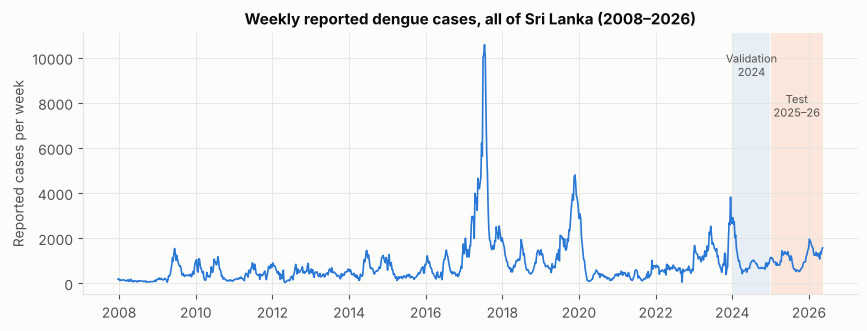

In [ ]:
nat = d.drop_duplicates(["district", "target_week_start"]).groupby("target_week_start").target_cases.sum()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(nat.index, nat.values, color=C1, lw=1.2)
for (a, b, lab, col, yy) in [(va.target_week_start.min(), va.target_week_start.max(), "Validation\n2024", "#e8eef6", 0.97),
                             (te.target_week_start.min(), te.target_week_start.max(), "Test\n2025–26", "#fbe6dc", 0.80)]:
    ax.axvspan(a, b, color=col, lw=0, zorder=0); ax.text(a + (b - a) / 2, nat.max() * yy, lab, fontsize=8, color=INK2, va="top", ha="center")
ax.set_ylabel("Reported cases per week"); ax.set_title("Weekly reported dengue cases, all of Sri Lanka (2008–2026)")
save("01_national_series.png")

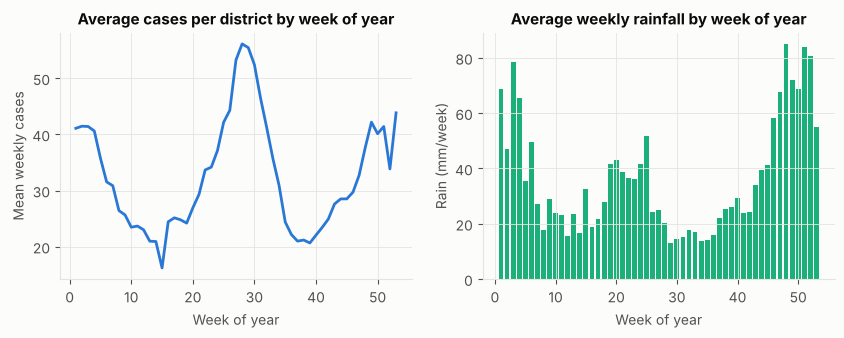

In [ ]:
season = d[d.split != "test"].groupby("target_week").agg(cases=("target_cases", "mean"), rain=("rain_l0", "mean"))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(season.index, season.cases, color=C1, lw=2); axs[0].set_title("Average cases per district by week of year")
axs[0].set_xlabel("Week of year"); axs[0].set_ylabel("Mean weekly cases")
axs[1].bar(season.index, season.rain, color=C3, width=0.8); axs[1].set_title("Average weekly rainfall by week of year")
axs[1].set_xlabel("Week of year"); axs[1].set_ylabel("Rain (mm/week)")
save("02_seasonality.png")

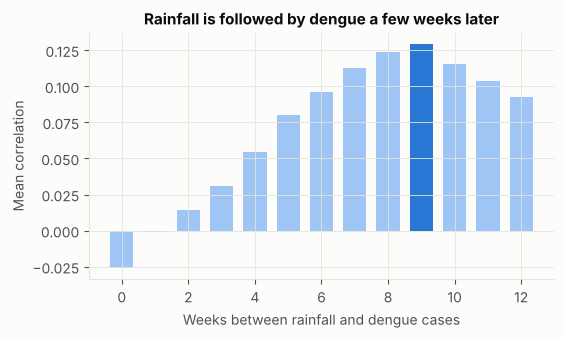

Correlation peaks at a lag of 9 weeks


In [ ]:
# Correlation between weekly rainfall and log cases k weeks later, averaged across districts
lag_corr = []
for k in range(0, 13):
    rs = [np.corrcoef(g.rain_l0.shift(k).iloc[k:], np.log1p(g.cases_l0).iloc[k:])[0, 1] for _, g in d[d.split != "test"].groupby("district")]
    lag_corr.append(np.nanmean(rs))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(range(0, 13), lag_corr, color=[C1 if i == int(np.argmax(lag_corr)) else LIGHT for i in range(13)], width=0.7)
ax.set_xlabel("Weeks between rainfall and dengue cases"); ax.set_ylabel("Mean correlation")
ax.set_title("Rainfall is followed by dengue a few weeks later"); save("03_rain_lag_correlation.png")
info["rain_lag_peak_weeks"] = int(np.argmax(lag_corr)); print("Correlation peaks at a lag of", info["rain_lag_peak_weeks"], "weeks")

## 4. Baselines (models covered in lectures)

* **Persistence**: forecast that cases in 4 weeks equal this week's cases (the standard epidemic-forecasting reference).
* Linear regression, k-NN (k = 10), decision tree and random forest, trained on the same features with a log(1 + cases) target.

Each model is fitted on 2008–2023 to score the 2024 validation set, then refitted on 2008–2024 and scored once on the 2025–2026 test set.

In [ ]:
results, preds = {}, {}
preds["Persistence (same as this week)"] = (va.cases_l0.values, te.cases_l0.values)
base_models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "k-NN (k=10)": make_pipeline(StandardScaler(), KNeighborsRegressor(10)),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=SEED),
    "Random Forest": RandomForestRegressor(400, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
}
for name, m in base_models.items():
    m.fit(tr[FEATURES], ylog(tr)); pv = np.expm1(m.predict(va[FEATURES])).clip(0)
    m.fit(trva[FEATURES], ylog(trva)); pt = np.expm1(m.predict(te[FEATURES])).clip(0)
    preds[name] = (pv, pt)
pd.DataFrame({k: metrics(va.target_cases, v[0]) for k, v in preds.items()}).T.round(3).rename_axis("Validation (2024)")

,MAE,RMSE,R2,RMSLE
Validation (2024),,,,
Persistence (same as this week),16.933,41.344,0.583,0.660
Linear Regression,19.488,59.216,0.146,0.687
k-NN (k=10),15.617,35.080,0.700,0.769
Decision Tree,15.307,35.600,0.691,0.618
Random Forest,11.805,27.968,0.809,0.533


## 5. CatBoost: tuning and final model

CatBoost is gradient boosting with **ordered boosting** (which reduces target leakage and overfitting) and **oblivious (symmetric) trees**.
The loss function is tuned like any other hyperparameter: squared error on log(1 + cases), **Poisson** and **Tweedie**. Tree depth and learning rate are also tuned.
Each run uses up to 4,000 trees with early stopping on the 2024 validation set. The selection criterion, fixed in advance, is **validation RMSE in cases**.

In [ ]:
LOSSES = {"RMSE on log(1+cases)": "RMSE", "Poisson": "Poisson", "Tweedie (p=1.5)": "Tweedie:variance_power=1.5"}
def to_y(loss, df): return np.log1p(df.target_cases) if loss == "RMSE" else df.target_cases
def from_pred(loss, p): return (np.expm1(p) if loss == "RMSE" else p).clip(0)
def fit_cb(train_df, feats=FEATURES, eval_df=None, params=None):
    P = dict(params or BP); loss = P.pop("loss")
    m = CatBoostRegressor(**P, loss_function=loss, random_seed=SEED, verbose=0,
                          **({"od_type": "Iter", "od_wait": 200} if eval_df is not None else {}))
    m.fit(train_df[feats], to_y(loss, train_df),
          eval_set=(eval_df[feats], to_y(loss, eval_df)) if eval_df is not None else None, use_best_model=eval_df is not None)
    m.loss_ = loss; return m
def cb_predict(m, df, feats=FEATURES): return from_pred(m.loss_, m.predict(df[feats]))

tuning = []
for (lname, loss), dep, lr in itertools.product(LOSSES.items(), [4, 6, 8], [0.03, 0.08]):
    m = fit_cb(tr, eval_df=va, params=dict(loss=loss, depth=dep, learning_rate=lr, l2_leaf_reg=3, iterations=4000))
    mv = metrics(va.target_cases, cb_predict(m, va))
    tuning.append({"loss": lname, "depth": dep, "learning_rate": lr, "best_iteration": int(m.get_best_iteration()) + 1,
                   "val_RMSE": mv["RMSE"], "val_MAE": mv["MAE"], "val_RMSLE": mv["RMSLE"]})
tun = pd.DataFrame(tuning).sort_values("val_RMSE").reset_index(drop=True); tun.round(4).to_csv(RES/"catboost_tuning.csv", index=False)
b = tun.iloc[0]
BP = dict(loss=LOSSES[b.loss], depth=int(b.depth), learning_rate=float(b.learning_rate), l2_leaf_reg=3.0, iterations=int(b.best_iteration))
BP_report = {**BP, "loss_name": b.loss}
print("Selected:", BP_report)
tun.round(3)

Selected: {'loss': 'Poisson', 'depth': 4, 'learning_rate': 0.03, 'l2_leaf_reg': 3.0, 'iterations': 1201, 'loss_name': 'Poisson'}


,loss,depth,learning_rate,best_iteration,val_RMSE,val_MAE,val_RMSLE
0,Poisson,4,0.03,1201,25.800,12.258,0.562
1,Tweedie (p=1.5),4,0.08,377,26.315,11.832,0.549
2,RMSE on log(1+cases),6,0.03,567,26.341,11.022,0.507
3,Poisson,4,0.08,488,26.370,12.265,0.562
4,Tweedie (p=1.5),4,0.03,972,26.540,11.966,0.552
5,RMSE on log(1+cases),4,0.03,948,26.815,11.011,0.505
6,RMSE on log(1+cases),8,0.03,396,27.012,11.074,0.505
7,Tweedie (p=1.5),6,0.03,727,27.048,11.826,0.545
8,RMSE on log(1+cases),4,0.08,435,27.366,11.530,0.512
9,RMSE on log(1+cases),6,0.08,217,27.951,11.220,0.512


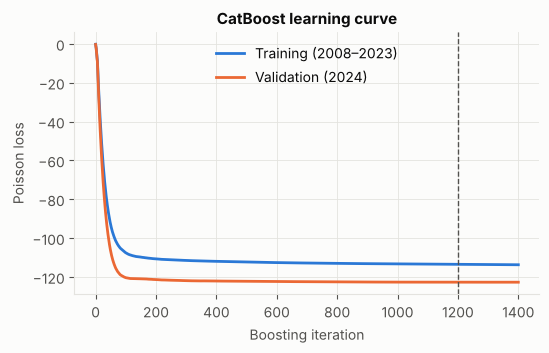

In [ ]:
# Learning curve on the validation year, then the final model refitted on 2008–2024 with the selected number of trees
cb_val = fit_cb(tr, eval_df=va, params={**BP, "iterations": 4000})
ev = cb_val.get_evals_result()
cb = fit_cb(trva)
cb.save_model(str(MOD/"catboost_dengue.cbm"))
preds["CatBoost (tuned)"] = (cb_predict(cb_val, va), cb_predict(cb, te))
for name, (pv, pt) in preds.items():
    results[name] = {"val": metrics(va.target_cases, pv), "test": metrics(te.target_cases, pt)}
p_te = preds["CatBoost (tuned)"][1]

key = list(ev["learn"].keys())[0]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(ev["learn"][key], color=C1, lw=2, label="Training (2008–2023)")
ax.plot(ev["validation"][key], color=C2, lw=2, label="Validation (2024)")
ax.axvline(cb_val.get_best_iteration(), color=INK2, ls="--", lw=1)
ax.set_xlabel("Boosting iteration"); ax.set_ylabel(f"{b.loss} loss"); ax.legend(); ax.set_title("CatBoost learning curve")
save("04_learning_curve.png")

## 6. Evaluation on the 2025–2026 test set

Metrics: **MAE** and **RMSE** (cases per week), **R²**, and **RMSLE** (relative error, so small districts count as much as large ones).

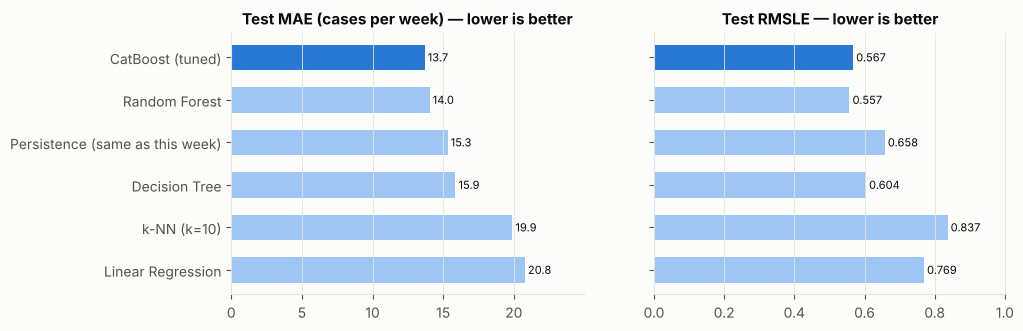

,MAE,RMSE,R2,RMSLE
Test (Jan 2025 – May 2026),,,,
Linear Regression,20.777,39.836,0.624,0.769
k-NN (k=10),19.891,39.563,0.629,0.837
Decision Tree,15.861,33.070,0.741,0.604
Persistence (same as this week),15.309,31.467,0.766,0.658
Random Forest,14.036,29.573,0.793,0.557
CatBoost (tuned),13.685,27.638,0.819,0.567


In [ ]:
order = ["Linear Regression", "k-NN (k=10)", "Decision Tree", "Persistence (same as this week)", "Random Forest", "CatBoost (tuned)"]
comp = pd.DataFrame({k: results[k]["test"] for k in order}).T
comp.round(3).to_csv(RES/"model_comparison_test.csv")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
o = comp.sort_values("MAE", ascending=False)
cols = [C1 if "CatBoost" in n else LIGHT for n in o.index]
for ax, met, lab, fmt in [(axs[0], "MAE", "Test MAE (cases per week) — lower is better", "{:.1f}"), (axs[1], "RMSLE", "Test RMSLE — lower is better", "{:.3f}")]:
    ax.barh(o.index, o[met], color=cols, height=0.6)
    for i, v in enumerate(o[met]): ax.text(v, i, " " + fmt.format(v), va="center", fontsize=8)
    ax.set_title(lab); ax.grid(axis="y", visible=False); ax.set_xlim(0, o[met].max() * 1.2)
axs[1].set_yticklabels([]); save("05_model_comparison.png")
comp.round(3).rename_axis("Test (Jan 2025 – May 2026)")

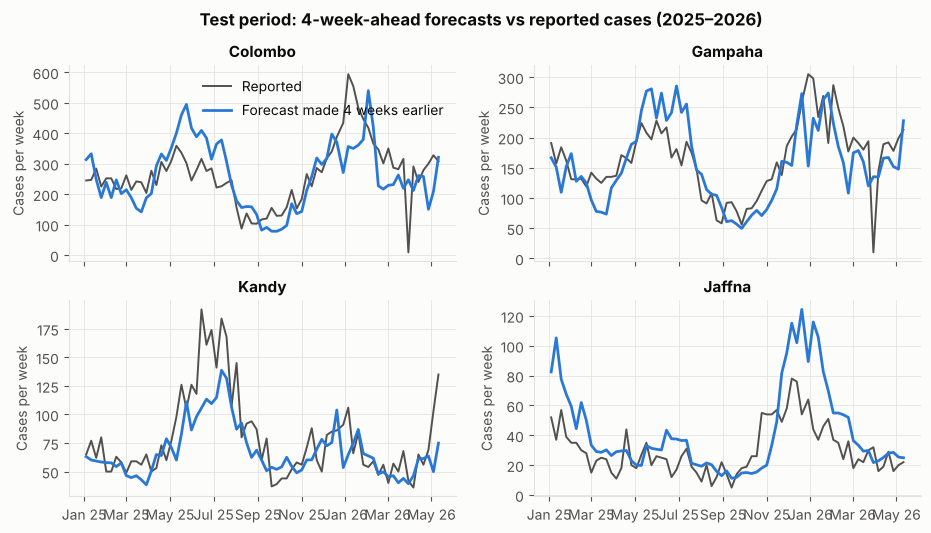

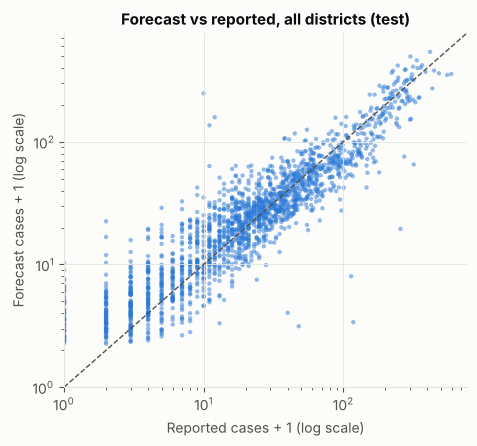

In [ ]:
show = ["Colombo", "Gampaha", "Kandy", "Jaffna"]
tp = te.assign(pred=p_te)
fig, axs = plt.subplots(2, 2, figsize=(11, 5.6), sharex=True)
for ax, dist in zip(axs.flat, show):
    g = tp[tp.district == dist]
    ax.plot(g.target_week_start, g.target_cases, color=INK2, lw=1.4, label="Reported")
    ax.plot(g.target_week_start, g.pred, color=C1, lw=2, label="Forecast made 4 weeks earlier")
    ax.set_title(dist); ax.set_ylabel("Cases per week"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
axs[0, 0].legend(loc="upper right"); fig.suptitle("Test period: 4-week-ahead forecasts vs reported cases (2025–2026)", fontweight="bold")
save("06_forecast_vs_actual.png")

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.scatter(te.target_cases + 1, p_te + 1, s=10, color=C1, alpha=0.5, edgecolor="none")
lim = [1, max(te.target_cases.max(), p_te.max()) * 1.3]; ax.plot(lim, lim, color=INK2, ls="--", lw=1)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Reported cases + 1 (log scale)"); ax.set_ylabel("Forecast cases + 1 (log scale)")
ax.set_title("Forecast vs reported, all districts (test)"); save("07_pred_vs_actual.png")

In [ ]:
# Error by district (CatBoost vs persistence)
per_d = tp.groupby("district").apply(lambda g: pd.Series({"mean_cases": g.target_cases.mean(), "MAE": mean_absolute_error(g.target_cases, g.pred),
        "persistence_MAE": mean_absolute_error(g.target_cases, g.cases_l0)}), include_groups=False).sort_values("mean_cases", ascending=False)
per_d.round(2).to_csv(RES/"error_by_district.csv")
print("CatBoost beats persistence in", int((per_d.MAE < per_d.persistence_MAE).sum()), "of", len(per_d), "districts")
per_d.round(2)

CatBoost beats persistence in 20 of 26 districts


,mean_cases,MAE,persistence_MAE
district,,,
Colombo,264.90,71.02,71.96
Gampaha,164.01,36.87,42.86
Ratnapura,93.83,31.57,38.06
Kandy,79.37,18.32,24.89
Galle,62.45,17.89,20.69
Kalutara,61.82,16.69,21.11
Matara,53.30,21.37,24.23
Batticaloa,36.01,17.38,16.13
Kegalle,34.58,10.42,13.45


In [ ]:
# Rolling-origin evaluation: each year is forecast by a model trained only on earlier years
rolling = []
for yr in range(2019, 2026):
    trn = d[d.target_week_start < f"{yr}-01-01"]; tst = d[(d.target_week_start >= f"{yr}-01-01") & (d.target_week_start < f"{yr+1}-01-01")]
    m = fit_cb(trn); p = cb_predict(m, tst)
    mm = metrics(tst.target_cases, p); pers = metrics(tst.target_cases, tst.cases_l0)
    rolling.append({"test_year": yr, "n": len(tst), "CatBoost_MAE": mm["MAE"], "Persistence_MAE": pers["MAE"],
                    "CatBoost_RMSE": mm["RMSE"], "Persistence_RMSE": pers["RMSE"], "CatBoost_RMSLE": mm["RMSLE"], "Persistence_RMSLE": pers["RMSLE"]})
rolling = pd.DataFrame(rolling); rolling.round(3).to_csv(RES/"rolling_origin.csv", index=False)
rolling.round(2)

,test_year,n,CatBoost_MAE,Persistence_MAE,CatBoost_RMSE,Persistence_RMSE,CatBoost_RMSLE,Persistence_RMSLE
0,2019,1352,29.80,27.26,73.19,59.76,0.63,0.68
1,2020,1352,14.27,16.91,30.06,40.47,0.98,0.94
2,2021,1352,10.08,10.44,24.18,26.44,0.86,0.93
3,2022,1378,14.09,14.86,24.29,24.84,0.84,0.98
4,2023,1352,26.70,28.69,57.51,62.09,0.83,1.02
5,2024,1352,12.26,16.93,25.80,41.34,0.56,0.66
6,2025,1352,11.74,13.00,23.47,24.71,0.54,0.61


In [ ]:
# High-risk week detection: a week is high-risk when cases exceed the district's 75th percentile (2008–2023)
q = tr.groupby("district").cases_l0.quantile([0.5, 0.75, 0.9]).unstack(); q.columns = ["p50", "p75", "p90"]
q.round(1).to_csv(RES/"district_thresholds.csv")
tt = te.join(q, on="district")
actual_high = (tt.target_cases > tt.p75).values; pred_score = p_te / tt.p75.values
alert = {"definition": "cases 4 weeks ahead above the district's 75th percentile (2008–2023)", "prevalence": float(actual_high.mean()),
         "CatBoost": {"precision": float(precision_score(actual_high, pred_score > 1)), "recall": float(recall_score(actual_high, pred_score > 1)),
                      "F1": float(f1_score(actual_high, pred_score > 1)), "AUC": float(roc_auc_score(actual_high, pred_score))},
         "Persistence": {"precision": float(precision_score(actual_high, tt.cases_l0 > tt.p75)), "recall": float(recall_score(actual_high, tt.cases_l0 > tt.p75)),
                         "F1": float(f1_score(actual_high, tt.cases_l0 > tt.p75)), "AUC": float(roc_auc_score(actual_high, tt.cases_l0 / tt.p75))}}
pd.DataFrame({k: alert[k] for k in ["CatBoost", "Persistence"]}).T.round(3)

,precision,recall,F1,AUC
CatBoost,0.660,0.813,0.728,0.795
Persistence,0.689,0.676,0.682,0.770


In [ ]:
# Feature-group ablation: retrain CatBoost without groups of inputs and score on the test set
ablation = {}
for lab, feats in {"District & season only": CONTEXT, "All features": FEATURES, "Without weather": CONTEXT + CASE,
                   "Without case history (weather + season + district)": CONTEXT + WEATHER}.items():
    m = fit_cb(trva, feats=feats); ablation[lab] = metrics(te.target_cases, cb_predict(m, te, feats))
pd.DataFrame(ablation).T.round(3)

,MAE,RMSE,R2,RMSLE
District & season only,20.331,41.845,0.585,0.695
All features,13.685,27.638,0.819,0.567
Without weather,12.911,26.690,0.831,0.555
Without case history (weather + season + district),21.856,45.847,0.502,0.736


## 7. Explainability

* **SHAP** (TreeExplainer): exact Shapley values for tree ensembles. With a Poisson loss, values are on the log scale, so a contribution of +0.1 multiplies the forecast by e^0.1 ≈ 1.105 (+10.5%).
* **Partial dependence with centred ICE curves**: how the forecast changes as one input varies.
* **CatBoost's built-in feature importance**, as a cross-check.

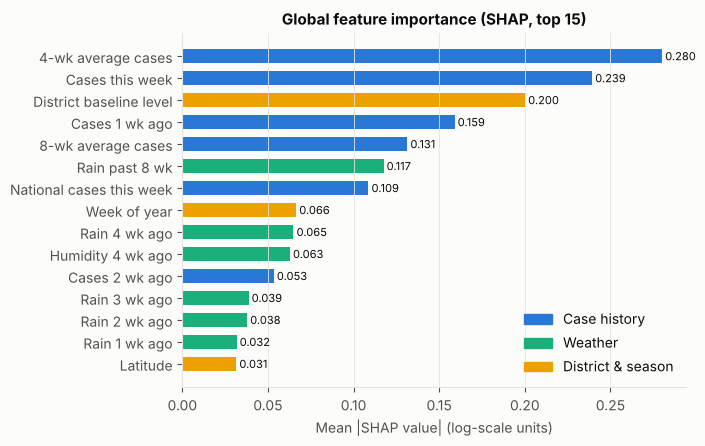

{'Case history': '57%', 'Weather': '26%', 'District & season': '18%'}


In [ ]:
explainer = shap.TreeExplainer(cb)
sv = explainer(te[FEATURES])
mean_abs = pd.Series(np.abs(sv.values).mean(0), index=FEATURES)
group_share = {g: float(mean_abs[f].sum() / mean_abs.sum()) for g, f in [("Case history", CASE), ("Weather", WEATHER), ("District & season", CONTEXT)]}
mabs = mean_abs.sort_values().tail(15)
fig, ax = plt.subplots(figsize=(6.5, 4.6))
colmap = {**{f: C1 for f in CASE}, **{f: C3 for f in WEATHER}, **{f: C4 for f in CONTEXT}}
ax.barh([NICE[f] for f in mabs.index], mabs.values, color=[colmap[f] for f in mabs.index], height=0.65)
for i, v in enumerate(mabs.values): ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
ax.set_xlabel("Mean |SHAP value| (log-scale units)"); ax.set_title("Global feature importance (SHAP, top 15)"); ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=C1, label="Case history"), Patch(color=C3, label="Weather"), Patch(color=C4, label="District & season")], loc="lower right")
save("08_shap_importance.png")
print({k: f"{100*v:.0f}%" for k, v in group_share.items()})

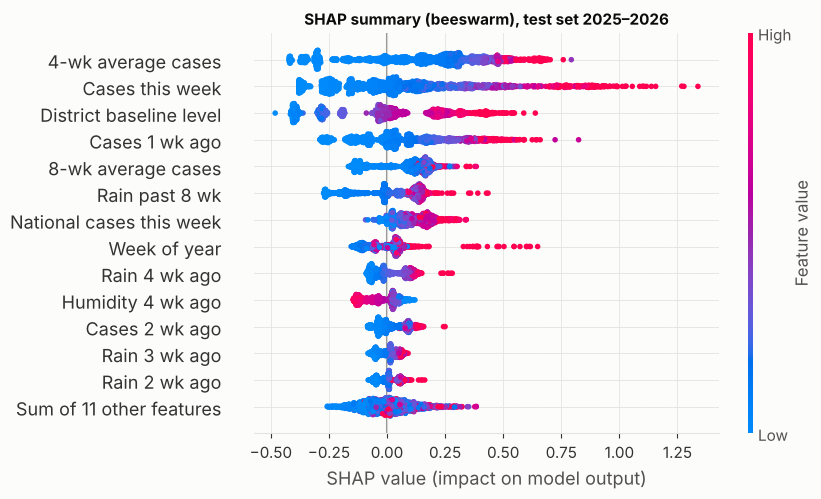

In [ ]:
sv_n = shap.Explanation(sv.values, sv.base_values, sv.data, feature_names=[NICE[f] for f in FEATURES])
plt.figure(); shap.plots.beeswarm(sv_n, max_display=14, show=False)
plt.gcf().set_size_inches(7.5, 5.2); plt.title("SHAP summary (beeswarm), test set 2025–2026"); save("09_shap_beeswarm.png")

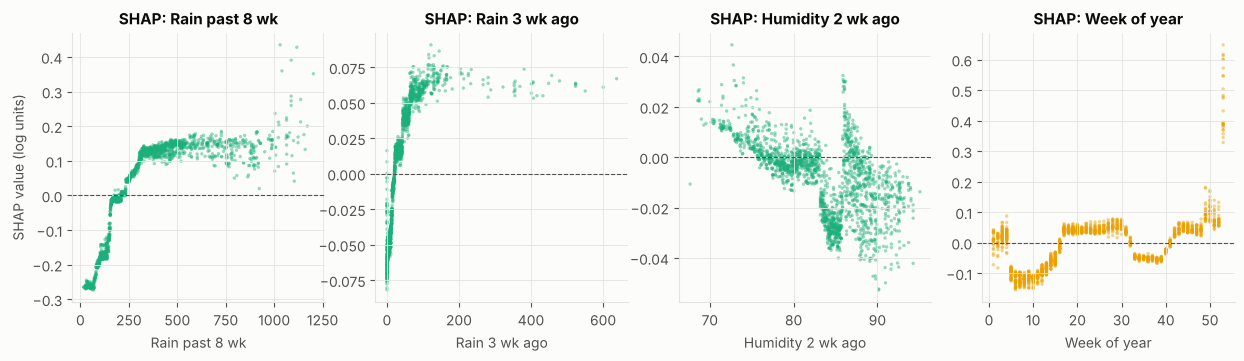

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, f, c in zip(axs, ["rain_sum8", "rain_l3", "hum_l2", "target_week"], [C3, C3, C3, C4]):
    i = FEATURES.index(f)
    ax.scatter(te[f], sv.values[:, i], s=6, color=c, alpha=0.45, edgecolor="none")
    ax.axhline(0, color=INK2, lw=0.8, ls="--"); ax.set_xlabel(NICE[f]); ax.set_title(f"SHAP: {NICE[f]}")
axs[0].set_ylabel("SHAP value (log units)"); save("10_shap_dependence.png")

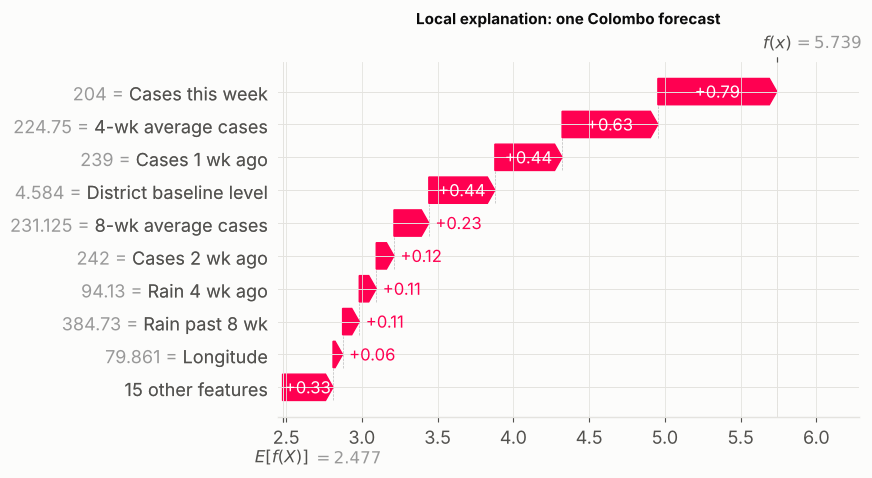

{'district': 'Colombo',
 'target_week_start': '2025-04-26',
 'actual': 276.0,
 'pred': 310.7506375335349,
 'cases_l0': 204.0,
 'base_log': 2.4766022963598457,
 'top': {'Cases this week': 0.7850948591895888,
  '4-wk average cases': 0.6322800405188298,
  'Cases 1 wk ago': 0.44367103041937694,
  'District baseline level': 0.43595992142212964,
  '8-wk average cases': 0.23014690728083775,
  'Cases 2 wk ago': 0.11703831989915046}}

In [ ]:
# Local explanation of one Colombo forecast during a rise in cases
mask = (te.district == "Colombo") & (te.target_cases > te.cases_l0 * 1.3) & (te.target_cases > 150)
i_loc = int(np.argmax(mask.values)) if mask.any() else int(np.argmax((te.district == "Colombo").values))
plt.figure(); shap.plots.waterfall(sv_n[i_loc], max_display=10, show=False)
plt.gcf().set_size_inches(7.5, 4.6); plt.title("Local explanation: one Colombo forecast"); save("11_shap_waterfall.png")
loc = te.iloc[i_loc]
local = {"district": loc.district, "target_week_start": str(loc.target_week_start.date()), "actual": float(loc.target_cases),
         "pred": float(p_te[i_loc]), "cases_l0": float(loc.cases_l0), "base_log": float(sv.base_values[i_loc]),
         "top": {NICE[f]: float(v) for f, v in sorted(zip(FEATURES, sv.values[i_loc]), key=lambda t: -abs(t[1]))[:6]}}
local

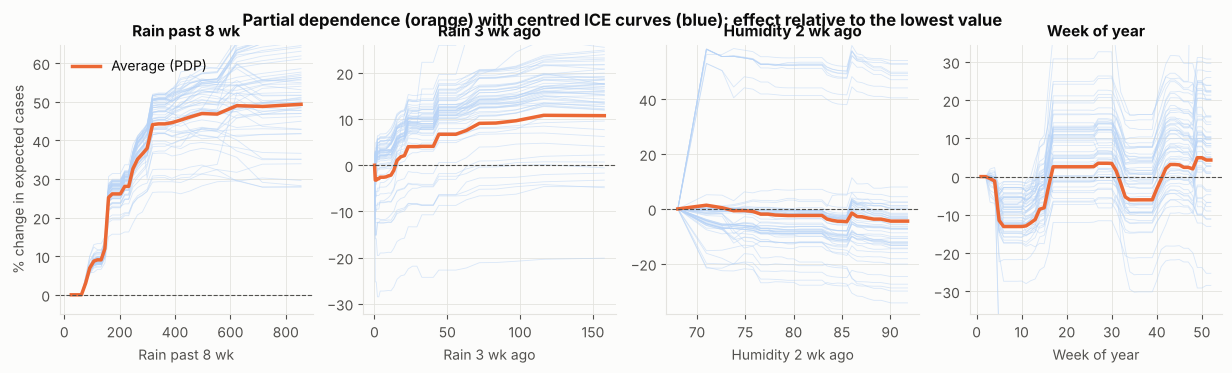

In [ ]:
# Partial dependence + centred ICE curves, shown as % change in expected cases
Xs = trva[FEATURES].astype(float).sample(1500, random_state=SEED).reset_index(drop=True)
pdp_feats = ["rain_sum8", "rain_l3", "hum_l2", "target_week"]
fig, axs = plt.subplots(1, 4, figsize=(15, 3.5)); pdp_out = {}
for ax, f in zip(axs, pdp_feats):
    grid_v = np.unique(np.quantile(trva[f], np.linspace(0.02, 0.98, 30))) if f != "target_week" else np.arange(1, 53)
    raw = np.empty((len(Xs), len(grid_v)))
    for j, v in enumerate(grid_v):
        Xg = Xs.copy(); Xg[f] = v; raw[:, j] = cb.predict(Xg[FEATURES], prediction_type="RawFormulaVal")
    ice = 100 * (np.exp(raw - raw[:, [0]]) - 1)
    pd_curve = 100 * (np.exp(raw.mean(0) - raw.mean(0)[0]) - 1)
    for r in ice[:60]: ax.plot(grid_v, r, color="#b7d3f6", lw=0.6, alpha=0.5)
    ax.plot(grid_v, pd_curve, color=C2, lw=2.5, label="Average (PDP)")
    ax.axhline(0, color=INK2, lw=0.8, ls="--"); ax.set_xlabel(NICE[f]); ax.set_title(NICE[f])
    lo, hi = np.percentile(ice, [2, 98]); ax.set_ylim(min(lo, pd_curve.min()) - 5, max(hi, pd_curve.max()) + 5)
    pdp_out[f] = {"x": [float(x) for x in grid_v], "pd_pct": [float(y) for y in pd_curve]}
axs[0].set_ylabel("% change in expected cases"); axs[0].legend(loc="upper left")
fig.suptitle("Partial dependence (orange) with centred ICE curves (blue): effect relative to the lowest value", fontweight="bold")
save("12_pdp_ice.png")

In [ ]:
imp = pd.DataFrame({"feature": [NICE[f] for f in FEATURES], "mean_abs_shap": mean_abs.values,
                    "catboost_native_%": cb.get_feature_importance()}).sort_values("mean_abs_shap", ascending=False)
imp.round(4).to_csv(RES/"feature_importance.csv", index=False)
imp.round(3).head(12)

,feature,mean_abs_shap,catboost_native_%
8,4-wk average cases,0.280,21.377
4,Cases this week,0.239,24.331
0,District baseline level,0.200,7.789
5,Cases 1 wk ago,0.159,11.898
9,8-wk average cases,0.131,9.344
17,Rain past 8 wk,0.117,4.397
11,National cases this week,0.109,4.143
3,Week of year,0.066,2.582
16,Rain 4 wk ago,0.065,1.082
23,Humidity 4 wk ago,0.063,1.217


In [ ]:
# Save all results used in the report
summary = {"horizon_weeks": HORIZON, "data": info, "best_params": BP_report, "results": results, "ablation": ablation, "alert": alert,
           "rolling_mean": {k: float(rolling[k].mean()) for k in rolling.columns if "_" in k},
           "shap_group_share": group_share, "pdp": pdp_out, "local_example": local, "features": FEATURES, "nice": NICE}
json.dump(summary, open(RES/"summary.json", "w"), indent=2)
print("Saved results/summary.json")

Saved results/summary.json


## 8. Front-end: export the model to a web app

The trained CatBoost model is exported to JSON and evaluated in the browser by a small JavaScript engine (`webapp/model.js`), which also computes exact TreeSHAP values.
The cells below write the engine and the page template, export the model and the 2025–2026 data, check the engine against Python if Node.js is available, and build **`webapp/index.html`**, a single file that opens in any browser.

In [ ]:
%%writefile webapp/model.js
/* CatBoost inference + exact path-dependent TreeSHAP for oblivious trees (raw log-scale output for Poisson models).
   Mirrors src/export_web_model.py (verified against catboost.predict and shap.TreeExplainer). */
(function (root) {
  function create(M) {
    const F = M.features.length;
    const fact = [1, 1, 2, 6, 24, 120];
    // Pre-process trees: distinct features and Shapley weights
    const trees = M.trees.map(t => {
      const U = [...new Set(t.f)];
      return { f: t.f, b: t.b, v: t.v, w: t.w, U, depth: t.f.length };
    });

    function leafIndex(t, x) {
      let idx = 0;
      for (let d = 0; d < t.depth; d++) if (x[t.f[d]] > t.b[d]) idx |= 1 << d;
      return idx;
    }

    function predict(x) {
      let s = M.bias;
      for (const t of trees) s += t.v[leafIndex(t, x)];
      return s;
    }

    function cover(t, mask, bits) {
      let c = 0;
      for (let l = 0; l < t.w.length; l++) if ((l & mask) === bits) c += t.w[l];
      return c;
    }

    // E[f | x_S] with unknown features split by training cover; root = last split (CatBoost order)
    function condExp(t, x, inS) {
      function rec(k, mask, bits, p) {
        if (k === t.depth) return p * t.v[bits];
        const d = t.depth - 1 - k, bit = 1 << d, f = t.f[d];
        if (inS(f)) return rec(k + 1, mask | bit, bits | (x[f] > t.b[d] ? bit : 0), p);
        const tot = cover(t, mask, bits);
        if (tot === 0) return 0;
        let out = 0;
        for (const c of [0, bit]) {
          const cw = cover(t, mask | bit, bits | c);
          if (cw) out += rec(k + 1, mask | bit, bits | c, p * cw / tot);
        }
        return out;
      }
      return rec(0, 0, 0, 1);
    }

    function shap(x) {
      const phi = new Array(F).fill(0);
      let base = M.bias;
      for (const t of trees) {
        const U = t.U, k = U.length, n = 1 << k;
        const v = new Array(n);
        for (let s = 0; s < n; s++) v[s] = condExp(t, x, f => { const i = U.indexOf(f); return i >= 0 && (s >> i) & 1; });
        base += v[0];
        for (let i = 0; i < k; i++) {
          const bi = 1 << i;
          for (let s = 0; s < n; s++) {
            if (s & bi) continue;
            let size = 0; for (let j = 0; j < k; j++) if ((s >> j) & 1) size++;
            phi[U[i]] += (fact[size] * fact[k - size - 1] / fact[k]) * (v[s | bi] - v[s]);
          }
        }
      }
      return { base, phi };
    }

    return { predict, shap, features: M.features };
  }
  if (typeof module !== "undefined" && module.exports) module.exports = { create };
  else root.TreeModel = { create };
})(this);


Overwriting webapp/model.js


In [ ]:
%%writefile webapp/app_template.html
<title>Dengue Outlook Sri Lanka</title>
<meta name="claude:viewport-fit-sides" content="cover">
<link rel="preconnect" href="https://fonts.googleapis.com">
<link rel="stylesheet" href="https://fonts.googleapis.com/css2?family=Bricolage+Grotesque:opsz,wght@12..96,600..800&family=Instrument+Sans:wght@400;500;600&family=JetBrains+Mono:wght@400;500&display=swap">
<style>
/* Layout: a district health officer's weekly brief. Controls on top; forecast + scenario on the left;
   evidence (history, explanation) on the right; island-wide ranking below. */
:root {
  --bg: #eef2f1;          /* pale lagoon grey */
  --panel: #fbfcfc;
  --ink: #0f1a1c;
  --ink-2: #48585b;
  --ink-3: #6d7d80;
  --line: #d3dcdb;
  --accent: #0d6b70;      /* lagoon teal */
  --accent-soft: #d6ebea;
  --reported: #3d4a4d;
  --forecast: #0d6b70;
  --up: #c2410c; --down: #2a78d6;
  --low: #0ca30c; --mod: #c98500; --high: #e0601f; --vhigh: #d03b3b;
  --low-bg: #e3f4e3; --mod-bg: #fbf0d6; --high-bg: #fbe5d9; --vhigh-bg: #f8dddd;
  --display: "Bricolage Grotesque", "Segoe UI", system-ui, sans-serif;
  --body: "Instrument Sans", system-ui, -apple-system, "Segoe UI", sans-serif;
  --mono: "JetBrains Mono", ui-monospace, Menlo, Consolas, monospace;
}
@media (prefers-color-scheme: dark) { :root:not([data-theme="light"]) {
  --bg: #0d1415; --panel: #152022; --ink: #e9f0ef; --ink-2: #b2c1c0; --ink-3: #869796; --line: #26383a;
  --accent: #4fb8b9; --accent-soft: #163a3c; --reported: #c9d5d4; --forecast: #4fb8b9; --up: #f08a5d; --down: #5598e7;
  --low: #3fbf3f; --mod: #e3a72f; --high: #f0844f; --vhigh: #ec6464;
  --low-bg: #16301a; --mod-bg: #362b0f; --high-bg: #3a2216; --vhigh-bg: #3d1a1a; color-scheme: dark; } }
:root[data-theme="dark"] {
  --bg: #0d1415; --panel: #152022; --ink: #e9f0ef; --ink-2: #b2c1c0; --ink-3: #869796; --line: #26383a;
  --accent: #4fb8b9; --accent-soft: #163a3c; --reported: #c9d5d4; --forecast: #4fb8b9; --up: #f08a5d; --down: #5598e7;
  --low: #3fbf3f; --mod: #e3a72f; --high: #f0844f; --vhigh: #ec6464;
  --low-bg: #16301a; --mod-bg: #362b0f; --high-bg: #3a2216; --vhigh-bg: #3d1a1a; color-scheme: dark; }

* { box-sizing: border-box; }
body { background: var(--bg); color: var(--ink); font: 15px/1.5 var(--body);
  padding-left: max(16px, env(safe-area-inset-left, 0px)); padding-right: max(16px, env(safe-area-inset-right, 0px)); padding-block: 20px 40px; }
.wrap { max-width: 1240px; margin: 0 auto; display: grid; gap: 18px; }
header { display: grid; gap: 14px; }
.brand { display: flex; flex-wrap: wrap; align-items: baseline; justify-content: space-between; gap: 6px 20px; }
h1 { font: 800 clamp(30px, 4.4vw, 44px)/1 var(--display); letter-spacing: -0.02em; margin: 0; text-wrap: balance; }
h1 em { font-style: normal; color: var(--accent); }
.sub { margin: 6px 0 0; color: var(--ink-2); max-width: 66ch; }
.src { font: 12px var(--mono); color: var(--ink-3); }
.controls { display: flex; flex-wrap: wrap; gap: 12px 16px; align-items: end; background: var(--panel); border: 1px solid var(--line); border-radius: 8px; padding: 12px 14px; }
.field { display: grid; gap: 3px; }
.field label { font-size: 11.5px; font-weight: 600; text-transform: uppercase; letter-spacing: 0.08em; color: var(--ink-3); }
select { font: 500 15px var(--body); color: var(--ink); background: var(--bg); border: 1px solid var(--line); border-radius: 6px; padding: 7px 10px; min-width: 190px; max-width: 100%; }
.controls .note { margin-left: auto; font-size: 13px; color: var(--ink-2); max-width: 46ch; }
select:focus-visible, input:focus-visible, button:focus-visible { outline: 2px solid var(--accent); outline-offset: 2px; }

.grid { display: grid; grid-template-columns: minmax(0, 400px) minmax(0, 1fr); gap: 18px; align-items: start; }
@media (max-width: 940px) { .grid { grid-template-columns: minmax(0, 1fr); } }
.panel { background: var(--panel); border: 1px solid var(--line); border-radius: 8px; padding: 18px; min-width: 0; }
.eyebrow { display: flex; justify-content: space-between; gap: 10px; font-size: 11.5px; font-weight: 600; text-transform: uppercase; letter-spacing: 0.09em; color: var(--ink-3); margin: 0 0 10px; }
h2 { font: 700 20px/1.2 var(--display); margin: 0 0 4px; }
.hint { color: var(--ink-2); font-size: 13.5px; margin: 0 0 12px; max-width: 70ch; }
.stack { display: grid; gap: 18px; min-width: 0; }

/* forecast card */
.fc-top { display: flex; align-items: flex-end; justify-content: space-between; gap: 12px; flex-wrap: wrap; }
.big { font: 800 clamp(60px, 9vw, 88px)/0.9 var(--display); letter-spacing: -0.03em; font-variant-numeric: tabular-nums; }
.big small { font: 600 15px var(--body); color: var(--ink-2); margin-left: 6px; letter-spacing: 0; }
.pill { display: inline-flex; align-items: center; gap: 6px; font-weight: 600; font-size: 14px; padding: 4px 11px 4px 8px; border-radius: 999px; white-space: nowrap; }
.pill svg { width: 15px; height: 15px; flex: none; }
.lvl-low { background: var(--low-bg); color: var(--low); } .lvl-mod { background: var(--mod-bg); color: var(--mod); }
.lvl-high { background: var(--high-bg); color: var(--high); } .lvl-vhigh { background: var(--vhigh-bg); color: var(--vhigh); }
.fc-cap { color: var(--ink-2); font-size: 14px; margin: 8px 0 12px; }
.scale { position: relative; height: 10px; border-radius: 5px; overflow: hidden; display: flex; margin: 4px 0 4px; }
.scale span { height: 100%; }
.scale-wrap { position: relative; margin-bottom: 18px; }
.scale-marker { position: absolute; top: -4px; width: 4px; height: 18px; border-radius: 2px; background: var(--ink); transform: translateX(-2px); }
.scale-labels { display: flex; justify-content: space-between; font: 11px var(--mono); color: var(--ink-3); }
.facts { display: grid; gap: 6px; }
.fact { display: flex; justify-content: space-between; gap: 12px; border-top: 1px solid var(--line); padding-top: 6px; font-size: 14px; }
.fact span:first-child { color: var(--ink-2); }
.fact b { font: 500 14px var(--mono); text-align: right; font-variant-numeric: tabular-nums; }

/* scenario inputs */
.scn-head { display: flex; justify-content: space-between; align-items: center; gap: 10px; margin-bottom: 6px; }
.tag { font-size: 12px; font-weight: 600; color: var(--accent); background: var(--accent-soft); padding: 2px 8px; border-radius: 4px; }
.btn { font: 600 13px var(--body); color: var(--ink); background: transparent; border: 1px solid var(--line); border-radius: 6px; padding: 5px 11px; cursor: pointer; }
.btn:hover { border-color: var(--ink-2); }
.btn:disabled { opacity: 0.45; cursor: default; }
.inputs { display: grid; grid-template-columns: repeat(4, minmax(0, 1fr)); gap: 8px; }
.inputs.w5 { grid-template-columns: repeat(5, minmax(0, 1fr)); }
.inputs.w2 { grid-template-columns: repeat(2, minmax(0, 1fr)); }
.in { display: grid; gap: 2px; min-width: 0; }
.in label { font-size: 11.5px; color: var(--ink-3); white-space: nowrap; overflow: hidden; text-overflow: ellipsis; }
@media (max-width: 460px) { .in input { padding-inline: 3px; font-size: 13px; } .inputs { gap: 6px; } }
.in input { width: 100%; min-width: 0; font: 500 14px var(--mono); color: var(--ink); background: var(--bg); border: 1px solid var(--line); border-radius: 5px; padding: 5px 6px; text-align: right; font-variant-numeric: tabular-nums; }
.in input.edited { border-color: var(--accent); background: var(--accent-soft); }
.grp { font-size: 12px; font-weight: 600; color: var(--ink-2); margin: 12px 0 6px; display: flex; justify-content: space-between; gap: 8px; }
.grp span { font-weight: 400; color: var(--ink-3); font-family: var(--mono); font-size: 11.5px; }

/* charts */
.chart { position: relative; min-width: 0; }
.chart svg { display: block; width: 100%; overflow: visible; }
.chart text { font-family: var(--body); fill: var(--ink-2); font-size: 11.5px; }
.chart .num { font-family: var(--mono); fill: var(--ink); font-size: 11.5px; font-variant-numeric: tabular-nums; }
.legend { display: flex; flex-wrap: wrap; gap: 14px; font-size: 12.5px; color: var(--ink-2); margin-top: 6px; }
.legend i { display: inline-block; width: 16px; height: 3px; border-radius: 2px; margin-right: 6px; vertical-align: 3px; }
.legend i.box { height: 10px; width: 12px; vertical-align: -1px; }
.tip { position: absolute; pointer-events: none; background: var(--ink); color: var(--panel); font-size: 12.5px; line-height: 1.4; padding: 6px 9px; border-radius: 5px; white-space: nowrap; transform: translate(-50%, calc(-100% - 10px)); z-index: 5; }
.tip b { font-family: var(--mono); font-weight: 500; }
.drivers { margin: 10px 0 0; font-size: 14px; color: var(--ink-2); }
.drivers b { color: var(--ink); font-weight: 600; }

/* ranking */
.rank { display: grid; grid-template-columns: repeat(auto-fill, minmax(min(100%, 330px), 1fr)); gap: 4px 22px; }
.rk { display: grid; grid-template-columns: 22px minmax(0, 1fr) 48px 96px; align-items: center; gap: 8px; padding: 5px 6px; border-radius: 5px; border: 1px solid transparent; background: none; font: inherit; color: inherit; text-align: left; cursor: pointer; width: 100%; }
.rk:hover { border-color: var(--line); }
.rk[aria-current="true"] { background: var(--accent-soft); }
.rk .n { font: 12px var(--mono); color: var(--ink-3); text-align: right; }
.rk .nm { font-weight: 500; white-space: nowrap; overflow: hidden; text-overflow: ellipsis; }
.rk .v { font: 500 13.5px var(--mono); text-align: right; font-variant-numeric: tabular-nums; }
.rk .pill { font-size: 12px; padding: 2px 8px 2px 6px; justify-self: start; }
.rk .pill svg { width: 12px; height: 12px; }

/* about */
.about { display: grid; grid-template-columns: minmax(0, 1fr) minmax(0, 1.05fr); gap: 24px; }
@media (max-width: 860px) { .about { grid-template-columns: minmax(0, 1fr); } }
.about p { margin: 0 0 10px; color: var(--ink-2); font-size: 14px; max-width: 66ch; }
.about p b { color: var(--ink); }
.tbl { overflow-x: auto; }
table { border-collapse: collapse; width: 100%; font-size: 13.5px; }
th, td { padding: 6px 8px; border-bottom: 1px solid var(--line); text-align: right; font-variant-numeric: tabular-nums; white-space: nowrap; }
th:first-child, td:first-child { text-align: left; }
th { font-size: 11.5px; font-weight: 600; text-transform: uppercase; letter-spacing: 0.07em; color: var(--ink-3); }
td { font-family: var(--mono); } td:first-child { font-family: var(--body); }
tr.best td { color: var(--accent); font-weight: 600; }
footer { text-align: center; font-size: 12.5px; color: var(--ink-3); }
</style>

<div class="wrap">
  <header>
    <div class="brand">
      <div>
        <h1>Dengue Outlook <em>Sri Lanka</em></h1>
        <p class="sub">Forecasts weekly dengue cases four weeks ahead for each of Sri Lanka's 26 health districts, from recent case reports and weather. Every forecast comes with an explanation.</p>
      </div>
      <span class="src">Data: Epidemiology Unit (MoH) · NASA POWER · 2025–26</span>
    </div>
    <div class="controls">
      <div class="field"><label for="sel-district">District</label><select id="sel-district"></select></div>
      <div class="field"><label for="sel-week">Latest reported week</label><select id="sel-week"></select></div>
      <p class="note" id="ctrl-note">The forecast uses data up to the selected week and predicts cases 4 weeks later.</p>
    </div>
  </header>

  <div class="grid">
    <div class="stack">
      <section class="panel" aria-labelledby="fc-h">
        <p class="eyebrow"><span id="fc-h">4-week forecast</span><span id="fc-week">–</span></p>
        <div class="fc-top">
          <div class="big" id="fc-val" aria-live="polite">–<small>cases</small></div>
          <span class="pill" id="fc-pill">–</span>
        </div>
        <p class="fc-cap" id="fc-cap">–</p>
        <div class="scale-wrap" aria-hidden="true">
          <div class="scale" id="scale"></div>
          <div class="scale-marker" id="scale-marker"></div>
          <div class="scale-labels" id="scale-labels"></div>
        </div>
        <div class="facts">
          <div class="fact"><span>Reported in the latest week</span><b id="f-now">–</b></div>
          <div class="fact"><span>Change expected</span><b id="f-chg">–</b></div>
          <div class="fact"><span id="f-act-l">Actually reported that week</span><b id="f-act">–</b></div>
        </div>
      </section>

      <section class="panel" aria-labelledby="scn-h">
        <div class="scn-head">
          <h2 id="scn-h">What if?</h2>
          <span class="tag" id="scn-tag" hidden>Edited scenario</span>
          <button class="btn" id="reset" type="button" disabled>Reset to reported data</button>
        </div>
        <p class="hint">These are the reported figures for the selected week. Change any value to see how the forecast responds.</p>
        <div class="grp">Dengue cases reported <span id="g-cases">4-wk avg –</span></div>
        <div class="inputs" id="in-cases"></div>
        <div class="grp">Rainfall, mm per week <span id="g-rain">8-wk total –</span></div>
        <div class="inputs w5" id="in-rain"></div>
        <div class="grp">This week's climate</div>
        <div class="inputs w2" id="in-clim"></div>
      </section>
    </div>

    <div class="stack">
      <section class="panel" aria-labelledby="hist-h">
        <p class="eyebrow"><span>Track record</span><span>Jan 2025 – May 2026</span></p>
        <h2 id="hist-h">Forecasts vs reported cases</h2>
        <p class="hint">Each forecast was made 4 weeks before the week shown, using only data available at the time. None of these weeks were used to train the model.</p>
        <div class="chart" id="hist"></div>
        <div class="legend"><span><i style="background:var(--reported)"></i>Reported</span><span><i style="background:var(--forecast)"></i>Forecast</span><span><i class="box" style="background:var(--vhigh-bg); border:1px solid var(--vhigh)"></i>Above district's 90th percentile</span></div>
      </section>

      <section class="panel" aria-labelledby="why-h">
        <p class="eyebrow"><span>Explanation</span><span>SHAP</span></p>
        <h2 id="why-h">Why this forecast?</h2>
        <p class="hint">The model starts from a typical district-week and adjusts it. Each bar shows how much one input raised or lowered the forecast, as a percentage.</p>
        <div class="chart" id="why"></div>
        <div class="legend"><span><i class="box" style="background:var(--up)"></i>Raises the forecast</span><span><i class="box" style="background:var(--down)"></i>Lowers the forecast</span></div>
        <p class="drivers" id="drivers"></p>
      </section>
    </div>
  </div>

  <section class="panel" aria-labelledby="rank-h">
    <p class="eyebrow"><span id="rank-h">Island-wide outlook</span><span id="rank-week">–</span></p>
    <h2>All districts, ranked by forecast</h2>
    <p class="hint">Risk levels compare each forecast with that district's own history (2008–2023), so a small district can be at high risk with fewer cases. Select a district to open it.</p>
    <div class="rank" id="rank"></div>
  </section>

  <section class="panel" aria-labelledby="about-h">
    <p class="eyebrow"><span id="about-h">About the model</span><span>Test period: 2025 – May 2026</span></p>
    <div class="about">
      <div>
        <p><b>Algorithm.</b> CatBoost gradient boosting with a Poisson loss for count data. It has 1,201 shallow trees and was tuned on 2024 data. It runs entirely in this page.</p>
        <p><b>Inputs.</b> Cases in the last four weeks, 4- and 8-week averages, cases in the same week last year, national cases, rainfall, temperature and humidity over the last few weeks, week of the year, and the district's usual dengue level.</p>
        <p><b>Data.</b> Weekly district case counts from the Epidemiology Unit, Ministry of Health, via the <i>denguedatahub</i> package. Daily weather from NASA POWER, summed to the same weeks.</p>
        <p><b>Use with care.</b> Reported cases depend on testing and reporting, which change over time. Weather is a coarse grid estimate. Treat this as an early-warning aid alongside field surveillance.</p>
      </div>
      <div class="tbl">
        <table id="metrics"><thead><tr><th>Model</th><th>MAE</th><th>RMSE</th><th>R²</th></tr></thead><tbody></tbody></table>
        <p class="hint" style="margin-top:8px">Errors in cases per week on 1,846 district-weeks from 2025–2026. For flagging weeks above a district's 75th percentile, the model scores F1 = <span id="m-f1"></span>.</p>
      </div>
    </div>
  </section>
  <footer>Machine Learning Assignment · MSc in Artificial Intelligence</footer>
</div>

<script>__MODEL_JS__</script>
<script>
const MODEL = __MODEL_JSON__;
const DATA = __DATA_JSON__;
(function () {
  const engine = TreeModel.create(MODEL);
  const F = MODEL.features, NICE = DATA.nice, C = DATA.cols, H = DATA.horizon;
  const col = name => C.indexOf(name);
  const fi = name => F.indexOf(name);
  // rows -> objects
  const rows = DATA.rows.map(r => {
    const o = { district: r[0], week: r[1], target: r[2], actual: r[3], rain57: r[4], cases47: r[5], x: r.slice(6) };
    o.raw = engine.predict(o.x); o.pred = Math.exp(o.raw); return o;
  });
  const districts = [...new Set(rows.map(r => r.district))].sort();
  const weeks = [...new Set(rows.map(r => r.week))].sort();
  const byKey = new Map(rows.map(r => [r.district + "|" + r.week, r]));
  const $ = id => document.getElementById(id);
  const fmt = (v, d = 0) => Number(v).toLocaleString("en-US", { minimumFractionDigits: d, maximumFractionDigits: d });
  const dateLbl = s => new Date(s + "T00:00:00").toLocaleDateString("en-GB", { day: "numeric", month: "short", year: "numeric" });
  const NS = "http://www.w3.org/2000/svg";
  const el = (t, a = {}, p) => { const e = document.createElementNS(NS, t); for (const k in a) e.setAttribute(k, a[k]); if (p) p.appendChild(e); return e; };
  const pretty = s => s.replace("NuwaraEliya", "Nuwara Eliya").replace("Hambanthota", "Hambantota").replace("Kalmune", "Kalmunai");

  const LEVELS = [
    { id: "low", name: "Low", icon: '<circle cx="8" cy="8" r="6" fill="none" stroke="currentColor" stroke-width="2"/><path d="M5 8.2l2 2 4-4.2" fill="none" stroke="currentColor" stroke-width="2" stroke-linecap="round"/>' },
    { id: "mod", name: "Moderate", icon: '<circle cx="8" cy="8" r="6" fill="none" stroke="currentColor" stroke-width="2"/><path d="M5 8h6" stroke="currentColor" stroke-width="2" stroke-linecap="round"/>' },
    { id: "high", name: "High", icon: '<path d="M8 2l6.5 11.5h-13z" fill="none" stroke="currentColor" stroke-width="1.8" stroke-linejoin="round"/><path d="M8 6.5v3.2" stroke="currentColor" stroke-width="1.8" stroke-linecap="round"/><circle cx="8" cy="11.6" r="1" fill="currentColor"/>' },
    { id: "vhigh", name: "Very high", icon: '<path d="M5.2 1.5h5.6l3.7 3.7v5.6l-3.7 3.7H5.2l-3.7-3.7V5.2z" fill="currentColor"/><path d="M8 4.6v4" stroke="var(--panel)" stroke-width="1.8" stroke-linecap="round"/><circle cx="8" cy="11.2" r="1" fill="var(--panel)"/>' },
  ];
  function level(dist, v) { const [p50, p75, p90] = DATA.thresholds[dist]; return LEVELS[v > p90 ? 3 : v > p75 ? 2 : v > p50 ? 1 : 0]; }
  function clampTip(box, tip) {
    const bw = box.clientWidth, tw = tip.offsetWidth;
    let x = parseFloat(tip.style.left) / 100 * bw;
    x = Math.min(Math.max(x, tw / 2 + 2), bw - tw / 2 - 2); tip.style.left = x + "px";
  }
  const pill = L => `<svg viewBox="0 0 16 16" aria-hidden="true">${L.icon}</svg>${L.name} risk`;

  // ---------- state ----------
  const state = { district: "Colombo", week: weeks[weeks.length - 1], edits: null };

  // ---------- controls ----------
  const sd = $("sel-district"), sw = $("sel-week");
  districts.forEach(d => sd.add(new Option(pretty(d), d)));
  [...weeks].reverse().forEach(w => sw.add(new Option("Week of " + dateLbl(w), w)));
  sd.addEventListener("change", () => { state.district = sd.value; state.edits = null; render(); });
  sw.addEventListener("change", () => { state.week = sw.value; state.edits = null; render(); });
  $("reset").addEventListener("click", () => { state.edits = null; render(); });

  const CASE_IN = [["cases_l0", "This week"], ["cases_l1", "1 wk ago"], ["cases_l2", "2 wk ago"], ["cases_l3", "3 wk ago"]];
  const RAIN_IN = [["rain_l0", "This wk"], ["rain_l1", "1 wk"], ["rain_l2", "2 wk"], ["rain_l3", "3 wk"], ["rain_l4", "4 wk"]];
  const CLIM_IN = [["temp_l0", "Mean temperature, °C"], ["hum_l0", "Relative humidity, %"]];
  const inputs = {};
  function buildInputs(box, list, step) {
    list.forEach(([k, lab]) => {
      const w = document.createElement("div"); w.className = "in";
      w.innerHTML = `<label for="i-${k}">${lab}</label><input id="i-${k}" type="number" min="0" step="${step}" inputmode="decimal">`;
      $(box).appendChild(w);
      const inp = w.querySelector("input"); inputs[k] = inp;
      inp.addEventListener("input", () => {
        if (inp.value === "" || isNaN(+inp.value)) return;
        state.edits = state.edits || {}; state.edits[k] = Math.max(0, +inp.value); schedule();
      });
    });
  }
  buildInputs("in-cases", CASE_IN, 1); buildInputs("in-rain", RAIN_IN, 1); buildInputs("in-clim", CLIM_IN, 0.1);

  // feature vector for current row + edits, recomputing derived features
  function vector(row, edits) {
    const x = row.x.slice();
    if (!edits) return x;
    for (const k in edits) x[fi(k)] = edits[k];
    const c = ["cases_l0", "cases_l1", "cases_l2", "cases_l3"].map(k => x[fi(k)]);
    x[fi("cases_ma4")] = c.reduce((a, b) => a + b) / 4;
    x[fi("cases_ma8")] = (c.reduce((a, b) => a + b) + row.cases47) / 8;
    x[fi("national_l0")] = row.x[fi("national_l0")] - row.x[fi("cases_l0")] + x[fi("cases_l0")];
    x[fi("rain_sum8")] = ["rain_l0", "rain_l1", "rain_l2", "rain_l3", "rain_l4"].map(k => x[fi(k)]).reduce((a, b) => a + b) + row.rain57;
    return x;
  }

  let raf = 0; function schedule() { if (!raf) raf = requestAnimationFrame(() => { raf = 0; renderForecast(); }); }

  function render() {
    sd.value = state.district; sw.value = state.week;
    const row = byKey.get(state.district + "|" + state.week);
    [...CASE_IN, ...RAIN_IN, ...CLIM_IN].forEach(([k]) => {
      const v = row.x[fi(k)]; inputs[k].value = (k.startsWith("cases") || k.startsWith("rain")) ? Math.round(v) : (Math.round(v * 10) / 10);
    });
    renderForecast(); drawHistory(); drawRanking();
  }

  function renderForecast() {
    const row = byKey.get(state.district + "|" + state.week);
    const x = vector(row, state.edits);
    const raw = engine.predict(x), pred = Math.exp(raw);
    const edited = !!state.edits;
    $("scn-tag").hidden = !edited; $("reset").disabled = !edited;
    [...CASE_IN, ...RAIN_IN, ...CLIM_IN].forEach(([k]) => inputs[k].classList.toggle("edited", !!(state.edits && k in state.edits)));
    $("g-cases").textContent = "4-wk avg " + fmt(x[fi("cases_ma4")], 1);
    $("g-rain").textContent = "8-wk total " + fmt(x[fi("rain_sum8")], 0) + " mm";

    const L = level(state.district, pred);
    $("fc-val").innerHTML = `${fmt(pred)}<small>cases</small>`;
    $("fc-pill").className = "pill lvl-" + L.id; $("fc-pill").innerHTML = pill(L);
    $("fc-week").textContent = "Week of " + dateLbl(row.target);
    const [p50, p75, p90] = DATA.thresholds[state.district];
    $("fc-cap").textContent = `Expected in ${pretty(state.district)} in the week of ${dateLbl(row.target)}. A typical week here has ${fmt(p50)} cases, and only 1 week in 10 exceeds ${fmt(p90)}.`;
    // risk scale
    const top = Math.max(p90 * 1.6, pred * 1.1), seg = [p50, p75 - p50, p90 - p75, top - p90];
    $("scale").innerHTML = seg.map((s, i) => `<span style="width:${100 * s / top}%;background:var(--${LEVELS[i].id})"></span>`).join("");
    $("scale-marker").style.left = Math.min(100, 100 * pred / top) + "%";
    $("scale-labels").innerHTML = `<span>0</span><span>p50 ${fmt(p50)}</span><span>p75 ${fmt(p75)}</span><span>p90 ${fmt(p90)}</span><span>${fmt(top)}</span>`;
    const now = x[fi("cases_l0")];
    $("f-now").textContent = fmt(now) + " cases";
    const ch = now > 0 ? 100 * (pred / now - 1) : null;
    $("f-chg").textContent = ch === null ? "–" : (ch >= 0 ? "+" : "−") + fmt(Math.abs(ch)) + "%";
    $("f-act-l").textContent = edited ? "Reported that week (unedited data)" : "Actually reported that week";
    $("f-act").textContent = fmt(row.actual) + " cases";
    drawWhy(engine.shap(x), raw, x);
  }

  // ---------- explanation waterfall (log scale, labelled in % change) ----------
  function drawWhy(s, raw, x) {
    const box = $("why"); box.innerHTML = "";
    const W = Math.max(300, box.clientWidth || 560);
    let items = F.map((f, i) => ({ f, v: s.phi[i] })).sort((a, b) => Math.abs(b.v) - Math.abs(a.v));
    const top = items.slice(0, 8), rest = items.slice(8).reduce((a, b) => a + b.v, 0);
    top.push({ f: "_other", v: rest });
    const rowH = 25, padT = 4, labW = Math.min(170, W * 0.36), valW = 54, L = labW + 8, R = W - valW;
    const n = top.length + 2, Hh = padT + n * rowH + 22;
    let run = s.base; const pts = [s.base]; top.forEach(d => { run += d.v; pts.push(run); });
    let lo = Math.min(...pts), hi = Math.max(...pts); const pad = Math.max(0.15, (hi - lo) * 0.08); lo -= pad; hi += pad;
    const sx = v => L + (R - L) * (v - lo) / (hi - lo);
    const svg = el("svg", { viewBox: `0 0 ${W} ${Hh}`, role: "img", "aria-label": "How each input changed the forecast" }, box);
    // ticks in cases on log scale
    [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000].forEach(c => {
      const v = Math.log(c); if (v < lo || v > hi) return;
      el("line", { x1: sx(v), x2: sx(v), y1: padT, y2: padT + n * rowH, stroke: "var(--line)" }, svg);
      const t = el("text", { x: sx(v), y: Hh - 5, "text-anchor": "middle", "font-size": 11 }, svg); t.textContent = fmt(c);
    });
    const tip = document.createElement("div"); tip.className = "tip"; tip.hidden = true; box.appendChild(tip);
    const label = f => f === "_other" ? `${F.length - 8} other inputs` : NICE[f];
    const valueOf = f => { const v = x[fi(f)]; return f.startsWith("rain") ? fmt(v, 0) + " mm" : f.startsWith("temp") ? fmt(v, 1) + " °C" : f.startsWith("hum") ? fmt(v, 0) + "%" :
                           f === "target_week" ? "week " + v : f === "district_level" ? "usual level" : (f === "lat" || f === "lon") ? fmt(v, 2) + "°" : fmt(v, 0) + " cases"; };
    function bar(i, lab, a0, a1, color, txt, tipHtml, bold) {
      const y = padT + i * rowH, a = Math.min(a0, a1), b = Math.max(a0, a1);
      const t = el("text", { x: 0, y: y + rowH / 2 + 4, fill: bold ? "var(--ink)" : "var(--ink-2)", "font-weight": bold ? 600 : 400 }, svg); t.textContent = lab;
      el("rect", { x: sx(a), y: y + 5, width: Math.max(2, sx(b) - sx(a)), height: rowH - 10, rx: 3, fill: color }, svg);
      const vt = el("text", { x: W, y: y + rowH / 2 + 4, "text-anchor": "end", class: "num", "font-weight": bold ? 600 : 400 }, svg); vt.textContent = txt;
      const hit = el("rect", { x: 0, y, width: W, height: rowH, fill: "transparent" }, svg);
      hit.addEventListener("pointerenter", () => { tip.hidden = false; tip.innerHTML = tipHtml; tip.style.left = ((sx(a) + sx(b)) / 2 / W * 100) + "%"; tip.style.top = (y + 4) / Hh * box.clientHeight + "px"; clampTip(box, tip); });
      hit.addEventListener("pointerleave", () => tip.hidden = true);
    }
    bar(0, "Typical district-week", lo, s.base, "var(--ink-3)", fmt(Math.exp(s.base)), `Average forecast across the training data: <b>${fmt(Math.exp(s.base))} cases</b>`, true);
    let acc = s.base;
    top.forEach((d, i) => {
      const y0 = acc; acc += d.v; const pct = 100 * (Math.exp(d.v) - 1);
      const txt = (pct >= 0 ? "+" : "−") + fmt(Math.abs(pct)) + "%";
      const tipHtml = d.f === "_other" ? `Combined effect of the remaining inputs: <b>${txt}</b>` : `${NICE[d.f]}: ${valueOf(d.f)}<br>${pct >= 0 ? "Raises" : "Lowers"} the forecast by <b>${fmt(Math.abs(pct))}%</b>`;
      bar(i + 1, label(d.f), y0, acc, d.v >= 0 ? "var(--up)" : "var(--down)", txt, tipHtml);
      const yy = padT + (i + 1) * rowH;
      el("line", { x1: sx(y0), x2: sx(y0), y1: yy - 5, y2: yy + 5, stroke: "var(--ink-3)", "stroke-dasharray": "2 2" }, svg);
    });
    bar(n - 1, "Forecast", lo, raw, "var(--accent)", fmt(Math.exp(raw)), `Forecast: <b>${fmt(Math.exp(raw))} cases</b>`, true);
    const t3 = top.filter(d => d.f !== "_other").slice(0, 3).map(d => { const p = 100 * (Math.exp(d.v) - 1); return `<b>${NICE[d.f].toLowerCase()}</b> (${p >= 0 ? "+" : "−"}${fmt(Math.abs(p))}%)`; });
    $("drivers").innerHTML = "Biggest influences: " + t3.join(", ") + ".";
  }

  // ---------- history chart ----------
  function drawHistory() {
    const box = $("hist"); box.innerHTML = "";
    const W = Math.max(300, box.clientWidth || 600), Hh = 250, L = 44, R = 12, T = 10, B = 28;
    const rs = rows.filter(r => r.district === state.district).sort((a, b) => a.target < b.target ? -1 : 1);
    const p90 = DATA.thresholds[state.district][2];
    const t0 = +new Date(rs[0].target), t1 = +new Date(rs[rs.length - 1].target);
    const ymax = Math.max(p90 * 1.15, ...rs.map(r => Math.max(r.actual, r.pred))) * 1.08;
    const sx = d => L + (W - L - R) * (+new Date(d) - t0) / (t1 - t0), sy = v => T + (Hh - T - B) * (1 - v / ymax);
    const svg = el("svg", { viewBox: `0 0 ${W} ${Hh}`, role: "img", "aria-label": "Reported and forecast cases, 2025 to 2026" }, box);
    el("rect", { x: L, y: T, width: W - L - R, height: Math.max(0, sy(p90) - T), fill: "var(--vhigh-bg)" }, svg);
    const step = ymax > 600 ? 200 : ymax > 250 ? 100 : ymax > 100 ? 50 : ymax > 40 ? 20 : 10;
    for (let v = 0; v <= ymax; v += step) {
      el("line", { x1: L, x2: W - R, y1: sy(v), y2: sy(v), stroke: "var(--line)" }, svg);
      const t = el("text", { x: L - 6, y: sy(v) + 4, "text-anchor": "end", "font-size": 11 }, svg); t.textContent = fmt(v);
    }
    ["2025-01-01", "2025-04-01", "2025-07-01", "2025-10-01", "2026-01-01", "2026-04-01"].forEach(m => {
      if (+new Date(m) < t0 || +new Date(m) > t1) return;
      const t = el("text", { x: sx(m), y: Hh - 8, "text-anchor": "middle", "font-size": 11 }, svg);
      t.textContent = new Date(m).toLocaleDateString("en-GB", { month: "short", year: "2-digit" });
    });
    const path = key => rs.map((r, i) => (i ? "L" : "M") + sx(r.target).toFixed(1) + "," + sy(r[key]).toFixed(1)).join("");
    el("path", { d: path("actual"), fill: "none", stroke: "var(--reported)", "stroke-width": 1.6, "stroke-linejoin": "round" }, svg);
    el("path", { d: path("pred"), fill: "none", stroke: "var(--forecast)", "stroke-width": 2.4, "stroke-linejoin": "round" }, svg);
    const cur = byKey.get(state.district + "|" + state.week);
    el("line", { x1: sx(cur.target), x2: sx(cur.target), y1: T, y2: Hh - B, stroke: "var(--ink-3)", "stroke-dasharray": "3 3" }, svg);
    el("circle", { cx: sx(cur.target), cy: sy(cur.pred), r: 5.5, fill: "var(--forecast)", stroke: "var(--panel)", "stroke-width": 2 }, svg);
    const cross = el("line", { y1: T, y2: Hh - B, stroke: "var(--ink-2)", visibility: "hidden" }, svg);
    const d1 = el("circle", { r: 4, fill: "var(--forecast)", stroke: "var(--panel)", "stroke-width": 2, visibility: "hidden" }, svg);
    const d2 = el("circle", { r: 4, fill: "var(--reported)", stroke: "var(--panel)", "stroke-width": 2, visibility: "hidden" }, svg);
    const tip = document.createElement("div"); tip.className = "tip"; tip.hidden = true; box.appendChild(tip);
    const hit = el("rect", { x: L, y: T, width: W - L - R, height: Hh - T - B, fill: "transparent", style: "cursor:pointer" }, svg);
    const nearest = ev => { const r = svg.getBoundingClientRect(), px = (ev.clientX - r.left) * W / r.width;
      let best = rs[0]; for (const q of rs) if (Math.abs(sx(q.target) - px) < Math.abs(sx(best.target) - px)) best = q; return best; };
    hit.addEventListener("pointermove", ev => {
      const q = nearest(ev);
      [cross].forEach(c => { c.setAttribute("x1", sx(q.target)); c.setAttribute("x2", sx(q.target)); c.setAttribute("visibility", "visible"); });
      d1.setAttribute("cx", sx(q.target)); d1.setAttribute("cy", sy(q.pred)); d1.setAttribute("visibility", "visible");
      d2.setAttribute("cx", sx(q.target)); d2.setAttribute("cy", sy(q.actual)); d2.setAttribute("visibility", "visible");
      tip.hidden = false; tip.style.left = (sx(q.target) / W * 100) + "%"; tip.style.top = (sy(Math.max(q.pred, q.actual)) / Hh * box.clientHeight) + "px";
      tip.innerHTML = `Week of ${dateLbl(q.target)}<br>Reported: <b>${fmt(q.actual)}</b> · Forecast: <b>${fmt(q.pred)}</b><br><span style="opacity:.75">Click to open this forecast</span>`;
      clampTip(box, tip);
    });
    hit.addEventListener("pointerleave", () => { tip.hidden = true; [cross, d1, d2].forEach(c => c.setAttribute("visibility", "hidden")); });
    hit.addEventListener("click", ev => { const q = nearest(ev); state.week = q.week; state.edits = null; render(); });
  }

  // ---------- ranking ----------
  function drawRanking() {
    const t = byKey.get(state.district + "|" + state.week).target;
    $("rank-week").textContent = "Forecast for week of " + dateLbl(t);
    const list = districts.map(d => byKey.get(d + "|" + state.week)).filter(Boolean)
      .map(r => ({ r, L: level(r.district, r.pred), ratio: r.pred / DATA.thresholds[r.district][2] }))
      .sort((a, b) => b.r.pred - a.r.pred);
    $("rank").innerHTML = "";
    list.forEach((it, i) => {
      const b = document.createElement("button"); b.type = "button"; b.className = "rk"; b.id = "rk-" + it.r.district;
      b.setAttribute("aria-current", String(it.r.district === state.district));
      b.innerHTML = `<span class="n">${i + 1}</span><span class="nm">${pretty(it.r.district)}</span><span class="v">${fmt(it.r.pred)}</span><span class="pill lvl-${it.L.id}"><svg viewBox="0 0 16 16" aria-hidden="true">${it.L.icon}</svg>${it.L.name}</span>`;
      b.addEventListener("click", () => { state.district = it.r.district; state.edits = null; render(); window.scrollTo({ top: 0, behavior: matchMedia("(prefers-reduced-motion: reduce)").matches ? "auto" : "smooth" }); });
      $("rank").appendChild(b);
    });
  }

  // ---------- model card ----------
  const order = ["Linear Regression", "k-NN (k=10)", "Decision Tree", "Persistence (same as this week)", "Random Forest", "CatBoost (tuned)"];
  order.forEach(k => { const m = DATA.metrics[k]; const tr = document.createElement("tr"); if (k.startsWith("CatBoost")) tr.className = "best";
    tr.innerHTML = `<td>${k.replace("Persistence (same as this week)", "Same as latest week")}</td><td>${fmt(m.MAE, 1)}</td><td>${fmt(m.RMSE, 1)}</td><td>${fmt(m.R2, 3)}</td>`;
    document.querySelector("#metrics tbody").appendChild(tr); });
  $("m-f1").textContent = fmt(DATA.alert.CatBoost.F1, 2) + ` (recall ${fmt(100 * DATA.alert.CatBoost.recall)}%)`;

  render();
  let rt; window.addEventListener("resize", () => { clearTimeout(rt); rt = setTimeout(() => { renderForecast(); drawHistory(); }, 120); });
})();
</script>


Overwriting webapp/app_template.html


In [ ]:
# Export the model (trees, splits, leaf values, leaf weights) and the test-period data for the app
tmp = WEB/"_full.json"; cb.save_model(str(tmp), format="json"); j = json.load(open(tmp)); tmp.unlink()
scale, bias = j["scale_and_bias"][0], j["scale_and_bias"][1][0]
trees = [{"f": [s["float_feature_index"] for s in t["splits"]], "b": [round(s["border"], 6) for s in t["splits"]],
          "v": [round(v * scale, 7) for v in t["leaf_values"]], "w": [int(w) for w in t["leaf_weights"]]} for t in j["oblivious_trees"]]
web_model = {"features": FEATURES, "bias": bias, "trees": trees, "link": "exp"}

tw = te.copy()
tw["cases_l4_7"] = tw.cases_ma8 * 8 - tw[["cases_l0", "cases_l1", "cases_l2", "cases_l3"]].sum(axis=1)   # lets the app recompute averages
tw["rain_l5_7"] = tw.rain_sum8 - tw[[f"rain_l{k}" for k in range(5)]].sum(axis=1)
keep = ["district", "week_start", "target_week_start", "target_cases", "rain_l5_7", "cases_l4_7"] + FEATURES
rows = [[r.district, str(r.week_start.date()), str(r.target_week_start.date()), float(r.target_cases), round(float(r.rain_l5_7), 2),
         round(float(r.cases_l4_7), 2)] + [round(float(r[f]), 4) for f in FEATURES] for _, r in tw[keep].iterrows()]
web_data = {"cols": keep, "rows": rows, "thresholds": {k: [float(v.p50), float(v.p75), float(v.p90)] for k, v in q.iterrows()},
            "coords": coords.set_index("district")[["lat", "lon", "province"]].to_dict("index"),
            "metrics": {k: v["test"] for k, v in results.items()}, "nice": NICE, "alert": alert, "horizon": HORIZON}
(WEB/"model.json").write_text(json.dumps(web_model, separators=(",", ":")))
(WEB/"data.json").write_text(json.dumps(web_data, separators=(",", ":")))
print(len(trees), "trees exported;", len(rows), "district-weeks for the app")

1201 trees exported; 1846 district-weeks for the app


In [ ]:
# Check the JavaScript engine against CatBoost and the SHAP library (needs Node.js; skipped if not installed)
if shutil.which("node"):
    import subprocess
    X = te[FEATURES].astype(float).sample(25, random_state=3)
    sv_chk = shap.TreeExplainer(cb)(X); raw_chk = cb.predict(X, prediction_type="RawFormulaVal")
    (WEB/"_x.json").write_text(json.dumps(X.values.tolist()))
    js = (f"const {{create}}=require('{(WEB/'model.js').as_posix()}');const M=create(require('{(WEB/'model.json').as_posix()}'));"
          f"const X=require('{(WEB/'_x.json').as_posix()}');console.log(JSON.stringify(X.map(x=>({{r:M.predict(x),...M.shap(x)}}))));")
    out = json.loads(subprocess.run(["node", "-e", js], capture_output=True, text=True, check=True).stdout); (WEB/"_x.json").unlink()
    err = {"prediction": max(abs(a["r"] - b) for a, b in zip(out, raw_chk)),
           "shap_values": max(float(np.abs(np.array(a["phi"]) - b).max()) for a, b in zip(out, sv_chk.values))}
    print("Largest difference between the browser engine and Python:", err)
else:
    print("Node.js not found: skipping the JavaScript check (the app still works).")

Largest difference between the browser engine and Python: {'prediction': np.float64(2.5817292865770725e-06), 'shap_values': 8.46855064962071e-07}


In [ ]:
# Build the single-file web app
html = ((WEB/"app_template.html").read_text().replace("__MODEL_JS__", (WEB/"model.js").read_text())
        .replace("__MODEL_JSON__", (WEB/"model.json").read_text()).replace("__DATA_JSON__", (WEB/"data.json").read_text()))
(WEB/"index.html").write_text(html)
print(f"Built webapp/index.html ({len(html)/1e6:.2f} MB). Open it in a browser to use the Dengue Outlook app.")
try:                                  # on Google Colab, offer the file for download
    from google.colab import files; files.download(str(WEB/"index.html"))
except ImportError:
    pass

Built webapp/index.html (0.74 MB). Open it in a browser to use the Dengue Outlook app.
